# Translation Analysis


This notebook explores similiarities between the different translations.

🛑 It is a first draft, so double check any results before using them.

This notebook:
- Loads one or more folders of JSONL files.
- Flattens translations into rows: id, language, event, text.
- Computes multilingual sentence embeddings and semantic similarities.
- Clusters similar translations per full set (or per scenario).
- Extracts medoids, runs lexical checks (chrF, Levenshtein), and entity-preservation audits.
- Outputs CSV reports and static plots.

# Normalization, JSONL loader, Embeddings, Cosine Similarity

## 1) Imports and configuration

In [1]:
# %pip install matplotlib seaborn sacrebleu python-Levenshtein sentence-transformers umap-learn scikit-learn plotly jinja2 ipywidgets
# # Optional stanza:
# %pip install stanza

# %pip install nbformat

In [2]:

import os, json, re, math
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sacrebleu
import stanza
import tqdm
import time

import Levenshtein
from sentence_transformers import SentenceTransformer, util
import umap
from sklearn.cluster import AgglomerativeClustering

from collections import defaultdict
from tqdm import tqdm
from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering

from sacrebleu.metrics import CHRF

sns.set_theme(style="whitegrid", rc={"figure.figsize": (10,6)})

# stanza optional
try:
    STANZA_OK = True
except Exception:
    STANZA_OK = False

print("STANZA available:", STANZA_OK)


STANZA available: True


## 2) Edit these parameters:

In [3]:
INPUT_DIRS = [
    "../data/processed/kc",
    "../data/processed/portland",
    # add more folders containing JSONL files here as needed
    # ex: "../data/processed/other_source",
]
OUTPUT_DIR = "../analysis_out"
SCENARIO_FILTER = None   # set to a scenario name to process one scenario, or None for all data
SAMPLE_LIMIT_PER_GROUP = None    # set int to limit rows per (lang,event) pair
EMBEDDING_MODEL = "paraphrase-multilingual-MiniLM-L12-v2"  # fast multilingual model
CLUSTER_DISTANCE_THRESHOLD = 0.35
DEVICE = None  # e.g., "cuda" or "cpu" or None (auto)
# ===============================

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Output dir:", OUTPUT_DIR)
print("Device:", DEVICE)
print("output directory (full path):", os.path.abspath(OUTPUT_DIR))

Output dir: ../analysis_out
Device: None
output directory (full path): /home/jen/TranslationsDataset/analysis_out


## 3) Normalize the text and load the JSONL files

In [4]:
import unicodedata

def normalize_text(s):
    if s is None:
        return ""
    s = str(s).strip()
    s = unicodedata.normalize("NFC", s)
    s = re.sub(r'\s+', ' ', s)
    return s

def iter_jsonl_paths(paths):
    for base in paths:
        base_path = os.path.abspath(base)
        if os.path.isfile(base_path) and base_path.endswith(".jsonl"):
            yield base_path
            continue
        for root, _, files in os.walk(base_path):
            for name in files:
                if name.endswith(".jsonl"):
                    yield os.path.join(root, name)

def load_jsonl_flat(paths, scenario_filter=None):
    print ("path: " + str(paths))
    rows = []
    jsonl_paths = list(iter_jsonl_paths(paths))

    for path in jsonl_paths:
        with open(path, "r", encoding="utf-8") as f:
            for ln in f:
                ln = ln.strip()
                if not ln:
                    continue
                obj = json.loads(ln)
                item_id = obj.get("id")
                scenario = obj.get("scenario") or obj.get("event")
                if scenario_filter and scenario != scenario_filter:
                    continue
                translations = obj.get("translations", {}) or {}
                # flatten translations
                for lang, text in translations.items():
                    if text is None or str(text).strip()=="":
                        continue
                    rows.append({
                        "id": str(item_id),
                        "language": str(lang),
                        "event": str(scenario) if scenario else "",
                        "text": normalize_text(text)
                    })
    df = pd.DataFrame(rows)
    print(f"Loaded {len(df)} translations from {len(jsonl_paths)} JSONL files (scenario_filter={scenario_filter})")
    # print the name of each loaded file
    # for path in jsonl_paths:  
    #     print(os.path.basename(path))
    return df

# Quick test load
print("Input directories (full paths):", [os.path.abspath(p) for p in INPUT_DIRS])
df = load_jsonl_flat(INPUT_DIRS, SCENARIO_FILTER)
if SAMPLE_LIMIT_PER_GROUP:
    df = df.groupby(['language','event']).head(SAMPLE_LIMIT_PER_GROUP).reset_index(drop=True)
len(df), df.language.unique()

Input directories (full paths): ['/home/jen/TranslationsDataset/data/processed/kc', '/home/jen/TranslationsDataset/data/processed/portland']
path: ['../data/processed/kc', '../data/processed/portland']
Loaded 43127 translations from 35 JSONL files (scenario_filter=None)


Input directories (full paths): ['/home/jen/TranslationsDataset/data/processed/kc', '/home/jen/TranslationsDataset/data/processed/portland']
path: ['../data/processed/kc', '../data/processed/portland']
Loaded 43127 translations from 35 JSONL files (scenario_filter=None)


(43127,
 array(['en', 'am', 'km', 'ko', 'lo', 'om', 'ru', 'zh', 'es', 'tl', 'th',
        'vi', 'so', 'uk', 'pa', 'fa', 'ja', 'hi', 'ar', 'my', 'chk', 'fr',
        'kar', 'mh', 'ne', 'ro', 'sw', 'te', 'hmn', 'ium', 'ps', 'rhg',
        'sr'], dtype=object))

## 4) Compute embeddings

In [5]:

model = SentenceTransformer(EMBEDDING_MODEL, device=DEVICE)
sentences = df['text'].tolist()
print("Encoding", len(sentences), "sentences with model", EMBEDDING_MODEL)
emb = model.encode(sentences, show_progress_bar=True, convert_to_tensor=False)
emb = np.array(emb)
np.save(os.path.join(OUTPUT_DIR, "embeddings.npy"), emb)
print("Saved embeddings.npy")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Encoding 43127 sentences with model paraphrase-multilingual-MiniLM-L12-v2


Batches:   0%|          | 0/1348 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Encoding 43127 sentences with model paraphrase-multilingual-MiniLM-L12-v2


Batches:   0%|          | 0/1348 [00:00<?, ?it/s]

Saved embeddings.npy


## 5) Compute cosine similarity matrix (batched)

In [6]:

def compute_pairwise_sim(emb, batch=256):
    n = emb.shape[0]
    sim = np.zeros((n,n), dtype=np.float32)
    norms = np.linalg.norm(emb, axis=1, keepdims=True)
    emb_n = emb / (norms + 1e-9)
    for i in range(0, n, batch):
        j_end = min(n, i + batch)
        block = emb_n[i:j_end]
        sim_block = np.dot(block, emb_n.T)
        sim[i:j_end, :] = sim_block
    return sim

sim = compute_pairwise_sim(emb, batch=256)
np.save(os.path.join(OUTPUT_DIR, "sim_matrix.npy"), sim)
print("Sim matrix shape:", sim.shape)

Sim matrix shape: (43127, 43127)


## 6) Clustering on normalized embeddings using AgglomerativeClustering

Save per-group CSVs (one file per language/event) + aggregated summary

Why clustering?

- groups near-duplicate translations so you can review patterns, not one line at a time.
- gives a representative medoid per cluster, which acts like a prototype example for that group.
- helps quality control by surfacing disagreements inside a cluster, where semantic similarity is high but wording or entities differ.
- reduces manual effort: you inspect cluster summaries first, then drill into flagged members.
- reveals systematic issues by language and event, such as templated wording, missing numbers, or entity drift.
- creates structure for downstream metrics and exports, so lexical checks and human review become targeted.

Clustering turns raw translations into coherent groups, prototypes, and prioritized error candidates.

## Edit these configuration variables as needed:

In [7]:
GROUP_KEYS = ['language', 'event']
# OUTPUT_DIR = globals().get('OUTPUT_DIR', './analysis_out')
PER_GROUP_DIR = os.path.join(OUTPUT_DIR, 'groups')
os.makedirs(PER_GROUP_DIR, exist_ok=True)
SAVE_PER_GROUP = True
CLUSTER_DISTANCE_THRESHOLD = globals().get('CLUSTER_DISTANCE_THRESHOLD', 0.35)
HUGELIMIT = 2000                 # if group size > HUGELIMIT use approximate medoid
USE_APPROX_MEDOID_FOR_LARGE = True


In [8]:
# Guard: ensure emb is numpy array and df index is default integer index aligned with emb rows
# convert embeddings to numpy
emb = np.asarray(emb)
assert emb.shape[0] == len(df), "embeddings length must match df rows"

# Normalized embeddings for clustering
emb_norm_all = normalize(emb, axis=1)

# Build groups, split by language and event (or scenario)
groups = defaultdict(list)
for idx, row in df.iterrows():
    key = (row['language'], row['event'])
    groups[key].append(int(idx))
print("Total groups:", len(groups))

# Helper: safe filename
def safe_filename(s: str) -> str:
    s = str(s)
    s = re.sub(r'[^\w\-_\. ]', '_', s)  # replace problematic chars
    s = s.replace(" ", "_")
    return s[:200]

all_cluster_rows = []

# Process each group
for (lang, event), indices in tqdm(groups.items(), desc="Groups", total=len(groups)):
    k = len(indices)
    if k == 0:  # skipping empty groups just in case
        continue

    # single item - trivial cluster with that one row as medoid
    if k == 1:
        i = indices[0]
        cluster_row = {
            'group_language': lang,
            'group_event': event,
            'cluster_label': 0,
            'size': 1,
            'medoid_global_index': int(i),
            'medoid_id': df.loc[i,'id'],
            'medoid_text': df.loc[i,'text'],
            'member_ids': json.dumps([df.loc[i,'id']])
        }
        all_cluster_rows.append(cluster_row)
        if SAVE_PER_GROUP:
            out_df = pd.DataFrame([{
                'cluster_label': 0,
                'medoid_id': df.loc[i,'id'],
                'medoid_text': df.loc[i,'text'],
                'member_ids': json.dumps([df.loc[i,'id']])
            }])
            fname = f"{safe_filename(lang)}__{safe_filename(event)}.csv"
            out_df.to_csv(os.path.join(PER_GROUP_DIR, fname), index=False)
        continue

    # slice embeddings for group (ensure integer indices)
    idx_arr = np.array(indices, dtype=int)
    emb_group = emb[idx_arr]
    emb_group_norm = emb_norm_all[idx_arr]

    # create clustering (compatibility)
    try:
        clustering = AgglomerativeClustering(
            n_clusters=None,
            distance_threshold=CLUSTER_DISTANCE_THRESHOLD,
            metric='euclidean',
            linkage='average'
        )
    except TypeError:
        clustering = AgglomerativeClustering(
            n_clusters=None,
            distance_threshold=CLUSTER_DISTANCE_THRESHOLD,
            linkage='average'
        )

    # run clustering with safety guard
    try:
        labels_local = clustering.fit_predict(emb_group_norm)
    except Exception as e:
        # fallback: assign everything to one cluster (or you can choose to skip)
        print(f"[WARN] clustering failed for group {lang}/{event} (size={k}): {e}. Falling back to single cluster.")
        labels_local = np.zeros(len(idx_arr), dtype=int)

    unique_labels = np.unique(labels_local)

    # compute pairwise sim unless group too large
    # find medoid per cluster (most central member) - either exact or approximate
    # if k < HUGELIMIT we can compute exact medoid using pairwise sims, otherwise use approximation to save memory/time
    approx_medoid = (USE_APPROX_MEDOID_FOR_LARGE and k > HUGELIMIT)
    if not approx_medoid:
        emb_gn = emb_group / (np.linalg.norm(emb_group, axis=1, keepdims=True) + 1e-9)
        sim_group = emb_gn @ emb_gn.T  # k x k

    per_group_records = []
    for lab in unique_labels:
        local_pos = np.where(labels_local == lab)[0].tolist()
        cluster_size = len(local_pos)
        if cluster_size == 1:
            med_local_pos = local_pos[0]
        else:
            if approx_medoid:
                members_emb = emb_group[local_pos]
                centroid = members_emb.mean(axis=0)
                norms = np.linalg.norm(members_emb, axis=1) * (np.linalg.norm(centroid) + 1e-9)
                sims = (members_emb @ centroid) / (norms + 1e-9)
                arg = int(np.argmax(sims))
                med_local_pos = local_pos[arg]
            else:
                sub = sim_group[np.ix_(local_pos, local_pos)]
                mean_sim = sub.mean(axis=1)
                arg = int(np.argmax(mean_sim))
                med_local_pos = local_pos[arg]

        med_global_idx = int(idx_arr[med_local_pos])
        member_global_ids = [df.loc[int(idx_arr[p]), 'id'] for p in local_pos]

        row = {
            'group_language': lang,
            'group_event': event,
            'cluster_label': int(lab),
            'size': int(cluster_size),
            'medoid_global_index': med_global_idx,
            'medoid_id': df.loc[med_global_idx, 'id'],
            'medoid_text': df.loc[med_global_idx, 'text'],
            'member_ids': json.dumps(member_global_ids)
        }
        # save the cluster
        all_cluster_rows.append(row)

        per_group_records.append({
            'cluster_label': int(lab),
            'size': int(cluster_size),
            'medoid_id': df.loc[med_global_idx, 'id'],
            'medoid_text': df.loc[med_global_idx, 'text'],
            'member_ids': json.dumps(member_global_ids)
        })

    if SAVE_PER_GROUP:
        fname = f"{safe_filename(lang)}__{safe_filename(event)}.csv"
        out_df = pd.DataFrame(per_group_records).sort_values('size', ascending=False)
        out_df.to_csv(os.path.join(PER_GROUP_DIR, fname), index=False)

# master summary
clusters_grouped_df = pd.DataFrame(all_cluster_rows).sort_values(['group_language','group_event','size'], ascending=[True,True,False])
clusters_grouped_df.to_csv(os.path.join(OUTPUT_DIR, "clusters_grouped.csv"), index=False)
print("Wrote per-group files to:", PER_GROUP_DIR)
print("Wrote summary:", os.path.join(OUTPUT_DIR, "clusters_grouped.csv"))

Total groups: 642


Groups: 100%|██████████| 642/642 [00:02<00:00, 226.63it/s]

Total groups: 642


Groups: 100%|██████████| 642/642 [00:02<00:00, 226.63it/s]

Wrote per-group files to: ../analysis_out/groups
Wrote summary: ../analysis_out/clusters_grouped.csv


## 7) Bridge grouped clusters to legacy objects used by downstream cells

This keeps later cells working: `clusters`, `clusters_df`, and `df['cluster']`

In [9]:
from tqdm.auto import tqdm

clusters_df = clusters_grouped_df.reset_index(drop=True).copy()
clusters_df['cluster_id'] = clusters_df.index.astype(int)

clusters = {}
df = df.copy()
df['cluster'] = -1

# Precompute id as string once to reduce repeated work in the loop
df_id_str = df['id'].astype(str)

total_clusters = len(clusters_df)
assigned_rows = 0
skipped_clusters = 0
start = time.time()

progress = tqdm(
    clusters_df.itertuples(index=False),
    total=total_clusters,
    desc="Combining grouped clusters",
    dynamic_ncols=True,
)

for n, r in enumerate(progress, start=1):
    cid = int(r.cluster_id)
    medoid_idx = int(r.medoid_global_index)

    # Resolve member row indices robustly using language/event + id
    member_ids = json.loads(r.member_ids) if isinstance(r.member_ids, str) else list(r.member_ids)
    member_idxs = []
    for mid in member_ids:
        hits = df.index[
            (df_id_str == str(mid))
            & (df['language'] == r.group_language)
            & (df['event'] == r.group_event)
        ].tolist()
        if hits:
            member_idxs.append(int(hits[0]))

    if not member_idxs:
        skipped_clusters += 1
        progress.set_postfix(assigned_rows=assigned_rows, skipped=skipped_clusters)
        continue

    # Ensure medoid is one of the members
    if medoid_idx not in member_idxs:
        medoid_idx = member_idxs[0]

    clusters[cid] = {
        'members': member_idxs,
        'medoid': medoid_idx,
    }
    df.loc[member_idxs, 'cluster'] = cid
    assigned_rows += len(member_idxs)

    # Refresh live stats periodically
    if n % 25 == 0 or n == total_clusters:
        progress.set_postfix(assigned_rows=assigned_rows, skipped=skipped_clusters)

elapsed = time.time() - start
assigned_unique = int((df['cluster'] >= 0).sum())

print(f"Built clusters dict with {len(clusters)} clusters (from {total_clusters} grouped rows)")
print(f"Rows assigned to a cluster: {assigned_unique} of {len(df)}")
print(f"Skipped grouped rows with no resolved members: {skipped_clusters}")
print(f"Combine time: {elapsed:.2f}s")

Combining grouped clusters:   0%|          | 0/38060 [00:00<?, ?it/s]

Combining grouped clusters:   0%|          | 0/38060 [00:00<?, ?it/s]

Built clusters dict with 38060 clusters (from 38060 grouped rows)
Rows assigned to a cluster: 43127 of 43127
Skipped grouped rows with no resolved members: 0
Combine time: 226.16s


In [10]:
# display some stats about cluster sizes
size_stats = clusters_df['size'].describe()
print("Cluster size stats:")
print(size_stats)

# display 3 clusters
n_show = min(3, len(clusters_df))
if n_show == 0:
    print("No clusters to display.")
else:
    random_idxs = np.random.choice(len(clusters_df), size=n_show, replace=False)
    for j, idx in enumerate(random_idxs, start=1):
        r = clusters_df.iloc[idx]
        print(f"\nRandom cluster {j} (row={idx}, lang={r.group_language}, event={r.group_event}, size={r.size}):")
        print(f"Medoid text: {r.medoid_text}")
        member_ids = json.loads(r.member_ids) if isinstance(r.member_ids, str) else list(r.member_ids)
        print(f"Member IDs: {member_ids}")

Cluster size stats:
count    38060.000000
mean         1.133132
std          0.999861
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         60.000000
Name: size, dtype: float64

Random cluster 1 (row=12194, lang=ja, event=earthquake, size=9):
Medoid text: 数日間は自活する準備をしてください。
Member IDs: ['kc-earthquake-012']

Random cluster 2 (row=16264, lang=ko, event=general, size=9):
Medoid text: Oregon Behavioral Health Support Line(오리건 주 행동건강 지원 전화)는 무료이며 기밀을 보장해 드립니다. 전화 통화 시 통역사의 도움을 받을 수 있습니다.
Member IDs: ['portland-general-061']

Random cluster 3 (row=4565, lang=en, event=landslides_and_mudflows, size=9):
Medoid text: If you have heart or lung diseases and your symptoms get worse around smoke, contact your healthcare provider. Call 911 if you or someone else has serious symptoms—like trouble breathing.
Member IDs: ['kc-landslides_and_mudflows-046']


## 8) Lexical metrics: chrF and Levenshtein (character-level) ratio

In [11]:
# Lexical metrics: chrF and Levenshtein ratio
chrf_metric = CHRF()

def chrF_score(hyp, ref):
    try:
        return float(chrf_metric.sentence_score(hyp, [ref]).score)
    except Exception:
        return 0.0

def levenshtein_ratio(a,b):
    if not a and not b:
        return 1.0
    if len(a)==0 or len(b)==0:
        return 0.0
    return Levenshtein.ratio(a,b)

# Simple entity extraction heuristics
NUMBER_RE = re.compile(r'[\d０-９]+(?:[.,:\/\-]\d+)*')
BRACKET_RE = re.compile(r'\[.*?\]')

def extract_simple_entities(text, lang=None):
    return {
        'numbers': NUMBER_RE.findall(text),
        'brackets': BRACKET_RE.findall(text),
        # stanza-based NER could be added here if desired
        'ner': []
    }

def compare_entities(ref_ent, hyp_ent):
    notes = []
    if set(ref_ent['numbers']) != set(hyp_ent['numbers']):
        notes.append('numbers_changed')
    if set(ref_ent['brackets']) != set(hyp_ent['brackets']):
        notes.append('bracketed_changed')
    return notes

flag_rows = []
for cl, info in clusters.items():
    med_idx = info['medoid']
    med_text = df.loc[med_idx, 'text']
    med_lang = df.loc[med_idx, 'language']
    for idx in info['members']:
        if idx == med_idx:
            continue
        hyp_text = df.loc[idx, 'text']
        chr = chrF_score(hyp_text, med_text)
        lev = levenshtein_ratio(hyp_text, med_text)
        sem = float(sim[idx, med_idx])
        ent_notes = compare_entities(extract_simple_entities(med_text, med_lang), extract_simple_entities(hyp_text, df.loc[idx,'language']))
        mismatch = []
        if sem >= 0.80 and chr < 30.0:
            mismatch.append('sem_high_lex_low')
        if sem < 0.60 and chr > 40.0:
            mismatch.append('lex_high_sem_low')
        if ent_notes:
            mismatch.append('entity_issue:' + ",".join(ent_notes))
        flag_rows.append({
            'id': df.loc[idx,'id'],
            'language': df.loc[idx,'language'],
            'event': df.loc[idx,'event'],
            'cluster_id': int(cl),
            'medoid_id': df.loc[med_idx,'id'],
            'medoid_text': med_text,
            'text': hyp_text,
            'chrF_vs_medoid': chr,
            'levenshtein_ratio_vs_medoid': lev,
            'semantic_sim_vs_medoid': sem,
            'entity_notes': json.dumps(ent_notes),
            'flags': ";".join(mismatch)
        })

flags_df = pd.DataFrame(flag_rows)
flags_df.to_csv(os.path.join(OUTPUT_DIR, "flags_vs_medoid.csv"), index=False)
print("Wrote flags_vs_medoid.csv with", len(flags_df), "rows")
flags_df.head()

Wrote flags_vs_medoid.csv with 5067 rows


,id,language,event,cluster_id,medoid_id,medoid_text,text,chrF_vs_medoid,levenshtein_ratio_vs_medoid,semantic_sim_vs_medoid,entity_notes,flags
0,portland-air_quality-060,am,air_quality,10,portland-air_quality-130,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,የልብ ወይም የሳንባ በሽታ ካለብዎ፣ ልጅ ወይም ትልቅ ሰው ከሆኑ ወይም ለ...,6.323220,0.266667,0.972777,[],sem_high_lex_low
1,portland-air_quality-084,am,air_quality,10,portland-air_quality-130,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,ከፊትዎ ጋር የሚስማማ እና ምንም ክፍተት የሌለበትን የጭምብል ልኬት እና ...,7.384364,0.330709,0.979582,[],sem_high_lex_low
2,portland-air_quality-088,am,air_quality,10,portland-air_quality-130,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,ጭምብል ማድረግ እንደ አስም ያሉ አንዳንድ የጤና ችግሮች ላለባቸው ሰዎች ...,7.042254,0.285714,0.963053,[],sem_high_lex_low
3,portland-air_quality-100,am,air_quality,10,portland-air_quality-130,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,የአየሩ ጥራት ጤናማ ካልሆነ ከቤት ውጭ የሚደረጉ እንቅስቃሴዎችን መሰረዝ ...,8.529416,0.338983,0.966675,[],sem_high_lex_low
4,portland-air_quality-119,am,air_quality,10,portland-air_quality-130,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,የካሊፎርኒያ ግዛት ጭስ ከአየር ላይ የሚያፀዱ የተረጋገጡ የአየር ማፅጃዎች...,7.736552,0.338710,0.968144,[],sem_high_lex_low


--------------

# Once you have run the above code, you have all the data you need for the code below. You don't need to rerun the above cells.

You might have to re-run the package import or variable declarations though.

-------------

## 1) Per-language similarity visualizations

### Load and Prepare

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

CSV_PATH = "../analysis_out/flags_vs_medoid.csv"

In [13]:

df = pd.read_csv(CSV_PATH, dtype=str).fillna("")

# Coerce numeric columns safely
for c in ['chrF_vs_medoid','levenshtein_ratio_vs_medoid','semantic_sim_vs_medoid']:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

# Quick row count and language counts
print("Rows:", len(df))
lang_counts = df['language'].value_counts()
print("Languages (top):")
display(lang_counts.head(30))

Rows: 5067
Languages (top):


language
kar    484
te     474
km     398
am     382
lo     340
so     178
zh     178
ja     175
ko     166
es     165
uk     163
th     163
ru     161
vi     160
en     158
fa     157
pa     140
tl     140
om     134
ium     85
ro      68
ne      65
ar      61
fr      61
sr      58
my      55
mh      54
hi      53
hmn     52
sw      42
Name: count, dtype: int64

--------------------

Violin plots

In [14]:
# One PNG per language with annotations (chrF + semantic), saved individually.
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import math, re, numpy as np

# CONFIG

# OUT_DIR = Path("analysis_out/language_plots_single")
# OUT_DIR.mkdir(parents=True, exist_ok=True)
FIGSIZE = (10,5)         # width, height per language image
DPI = 200
VIOLIN_KW = dict(inner='box', density_norm='width', cut=0)

# check that the output_dir is still correct
OUTPUT_DIR = Path(os.path.abspath(OUTPUT_DIR))
print("Output dir for plots:", OUTPUT_DIR)

Output dir for plots: /home/jen/TranslationsDataset/analysis_out


In [15]:


# helpers
def safe_name(s):
    s = str(s)
    s = re.sub(r'[^\w\-_\. ]', '_', s)
    s = s.replace(" ", "_")
    return s[:120]

# load data
df = pd.read_csv(CSV_PATH, dtype=str).fillna("")
for c in ['chrF_vs_medoid','semantic_sim_vs_medoid','levenshtein_ratio_vs_medoid']:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

# languages to plot (all)
languages = sorted(df['language'].unique())
print("Languages to render:", len(languages))

for lang in languages:
    sub = df[df['language']==lang].copy()
    n = len(sub)
    if n == 0:
        continue

    # compute annotation stats
    sem_median = sub['semantic_sim_vs_medoid'].median() if 'semantic_sim_vs_medoid' in sub else np.nan
    sem_q25 = sub['semantic_sim_vs_medoid'].quantile(0.25) if 'semantic_sim_vs_medoid' in sub else np.nan
    sem_q75 = sub['semantic_sim_vs_medoid'].quantile(0.75) if 'semantic_sim_vs_medoid' in sub else np.nan

    chrf_median = sub['chrF_vs_medoid'].median() if 'chrF_vs_medoid' in sub else np.nan
    chrf_q25 = sub['chrF_vs_medoid'].quantile(0.25) if 'chrF_vs_medoid' in sub else np.nan
    chrf_q75 = sub['chrF_vs_medoid'].quantile(0.75) if 'chrF_vs_medoid' in sub else np.nan

    # percent flagged
    pct_flagged = (sub['flags'].astype(bool).sum() / n) * 100.0 if 'flags' in sub else 0.0

    # create figure with two violins side by side
    fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, constrained_layout=True)
    fig.suptitle(f"Language: {lang}  (n={n})", fontsize=14)

    # chrF violin (0..100)
    ax = axes[0]
    sns.violinplot(data=sub, x='language', y='chrF_vs_medoid', order=[lang], ax=ax, **VIOLIN_KW)
    ax.set_ylim(0, 100)
    ax.set_ylabel("chrF_vs_medoid")
    ax.set_xlabel("")
    # annotation text near top-left of subplot
    ax.text(0, 105, f"count={n}\nmedian={chrf_median:.1f}\nIQR={chrf_q25:.1f}-{chrf_q75:.1f}\n% flagged={pct_flagged:.1f}%", 
            fontsize=9, va='top')

    # semantic violin (0..1)
    ax2 = axes[1]
    sns.violinplot(data=sub, x='language', y='semantic_sim_vs_medoid', order=[lang], ax=ax2, **VIOLIN_KW)
    ax2.set_ylim(0, 1.0)
    ax2.set_ylabel("semantic_sim_vs_medoid")
    ax2.set_xlabel("")
    ax2.text(0, 1.02, f"median={sem_median:.3f}\nIQR={sem_q25:.3f}-{sem_q75:.3f}", fontsize=9, va='top')

    # optionally annotate outlier counts
    low_chrf_count = int((sub['chrF_vs_medoid'] < 20).sum()) if 'chrF_vs_medoid' in sub else 0
    low_sem_count = int((sub['semantic_sim_vs_medoid'] < 0.6).sum()) if 'semantic_sim_vs_medoid' in sub else 0
    axes[0].annotate(f"low chrF (<20): {low_chrf_count}", xy=(0,5), xycoords='data', fontsize=9, color='red')
    axes[1].annotate(f"low sem (<0.6): {low_sem_count}", xy=(0,0.05), xycoords='data', fontsize=9, color='red')

    # Save PNG: one file per language
    fname = OUTPUT_DIR / f"{safe_name(lang)}.png"
    fig.savefig(fname, dpi=DPI, bbox_inches='tight')
    plt.close(fig)
    print("Saved", fname)

print("All plots written to", OUTPUT_DIR)

Languages to render: 33
Saved /home/jen/TranslationsDataset/analysis_out/am.png
Saved /home/jen/TranslationsDataset/analysis_out/ar.png
Saved /home/jen/TranslationsDataset/analysis_out/chk.png
Saved /home/jen/TranslationsDataset/analysis_out/en.png
Saved /home/jen/TranslationsDataset/analysis_out/es.png
Saved /home/jen/TranslationsDataset/analysis_out/fa.png
Saved /home/jen/TranslationsDataset/analysis_out/fr.png
Saved /home/jen/TranslationsDataset/analysis_out/hi.png
Saved /home/jen/TranslationsDataset/analysis_out/hmn.png
Saved /home/jen/TranslationsDataset/analysis_out/ium.png
Saved /home/jen/TranslationsDataset/analysis_out/ja.png
Saved /home/jen/TranslationsDataset/analysis_out/kar.png
Saved /home/jen/TranslationsDataset/analysis_out/km.png
Saved /home/jen/TranslationsDataset/analysis_out/ko.png
Saved /home/jen/TranslationsDataset/analysis_out/lo.png
Saved /home/jen/TranslationsDataset/analysis_out/mh.png
Saved /home/jen/TranslationsDataset/analysis_out/my.png
Saved /home/jen/Tran

## 2) scatter semantic vs chrF (sampled)

In [16]:
# # scatter sample for readability
# sample_n = 2000
# if len(df_top) > sample_n:
#     sampled = df_top.sample(sample_n, random_state=42)
# else:
#     sampled = df_top

# plt.figure(figsize=(9,7))
# sns.scatterplot(data=sampled, x='semantic_sim_vs_medoid', y='chrF_vs_medoid', hue='language', palette='tab20', s=30, alpha=0.8)
# plt.xlim(.8,1.1)
# plt.ylim(0,100)
# plt.title("semantic_sim_vs_medoid vs chrF_vs_medoid (sampled)")
# plt.legend(bbox_to_anchor=(1.05,1), loc='upper left', ncol=1)
# plt.tight_layout()
# plt.savefig("semantic_vs_chrf_scatter.png", dpi=200)
# plt.show()

## 3) summary table per language

In [17]:
summary = df.groupby('language').agg(
    n = ('semantic_sim_vs_medoid','count'),
    sem_median = ('semantic_sim_vs_medoid','median'),
    sem_q25 = ('semantic_sim_vs_medoid', lambda s: s.quantile(0.25)),
    sem_q75 = ('semantic_sim_vs_medoid', lambda s: s.quantile(0.75)),
    chrf_median = ('chrF_vs_medoid','median'),
    chrf_q25 = ('chrF_vs_medoid', lambda s: s.quantile(0.25)),
    chrf_q75 = ('chrF_vs_medoid', lambda s: s.quantile(0.75))
).sort_values('n', ascending=False).reset_index()

summary.to_csv("language_similarity_summary.csv", index=False)
display(summary.head(50))
print("Saved language_similarity_summary.csv")

,language,n,sem_median,sem_q25,sem_q75,chrf_median,chrf_q25,chrf_q75
0,kar,484,0.970134,0.957812,0.981342,24.472318,19.004637,35.124900
1,te,474,0.972492,0.959064,0.986253,17.849603,14.511739,27.366498
2,km,398,0.975141,0.959223,0.993517,24.630417,15.851715,94.765085
3,am,382,0.971618,0.958285,0.988193,11.797887,7.918540,93.775956
4,lo,340,0.979493,0.963851,1.000000,34.786792,20.653811,100.000000
5,so,178,1.000000,0.970744,1.000000,100.000000,83.685938,100.000000
6,zh,178,1.000000,0.970761,1.000000,100.000000,77.164679,100.000000
7,ja,175,1.000000,0.960374,1.000000,100.000000,75.287236,100.000000
8,ko,166,1.000000,0.973010,1.000000,100.000000,77.942607,100.000000
9,es,165,1.000000,0.980436,1.000000,100.000000,84.605308,100.000000


Saved language_similarity_summary.csv



## filter for suspicious patterns

In [18]:
# semantic high but low chrF (paraphrase-like or tokenization mismatch)
candidates = df[(df['semantic_sim_vs_medoid'] >= 0.8) & (df['chrF_vs_medoid'] < 30)]
print("Semantic>=0.8 & chrF<30: ", len(candidates))
display(candidates[['id','language','cluster_id','medoid_id','chrF_vs_medoid','semantic_sim_vs_medoid','flags']].head(50))

# semantic low but high chrF (possible misalignment)
candidates2 = df[(df['semantic_sim_vs_medoid'] < 0.6) & (df['chrF_vs_medoid'] > 40)]
print("Semantic<0.6 & chrF>40: ", len(candidates2))
display(candidates2[['id','language','cluster_id','medoid_id','chrF_vs_medoid','semantic_sim_vs_medoid','flags']].head(50))

Semantic>=0.8 & chrF<30:  1435


Semantic>=0.8 & chrF<30:  1435


,id,language,cluster_id,medoid_id,chrF_vs_medoid,semantic_sim_vs_medoid,flags
0,portland-air_quality-060,am,10,portland-air_quality-130,6.323220,0.972777,sem_high_lex_low
1,portland-air_quality-084,am,10,portland-air_quality-130,7.384364,0.979582,sem_high_lex_low
2,portland-air_quality-088,am,10,portland-air_quality-130,7.042254,0.963053,sem_high_lex_low
3,portland-air_quality-100,am,10,portland-air_quality-130,8.529416,0.966675,sem_high_lex_low
4,portland-air_quality-119,am,10,portland-air_quality-130,7.736552,0.968144,sem_high_lex_low
5,portland-air_quality-126,am,10,portland-air_quality-130,8.345306,0.975369,sem_high_lex_low
6,portland-air_quality-140,am,10,portland-air_quality-130,4.350736,0.958354,sem_high_lex_low
7,portland-air_quality-145,am,10,portland-air_quality-130,14.318381,0.981978,sem_high_lex_low
8,portland-air_quality-152,am,10,portland-air_quality-130,6.365629,0.967227,sem_high_lex_low
10,portland-air_quality-173,am,10,portland-air_quality-130,14.374574,0.983969,sem_high_lex_low


Semantic<0.6 & chrF>40:  0


,id,language,cluster_id,medoid_id,chrF_vs_medoid,semantic_sim_vs_medoid,flags


## 4) UMAP scatter colored by cluster

In [19]:
import warnings
import time

In [20]:

# # UMAP can warn when random_state disables parallelism; this is expected and harmless
# warnings.filterwarnings(
#     "ignore",
#     message="n_jobs value 1 overridden to 1 by setting random_state",
#     category=UserWarning,
# )

# # Add tiny jitter to reduce exact-duplicate geometry issues that can hurt spectral init
# rng = np.random.default_rng(42)
# emb_umap = emb + rng.normal(0.0, 1e-8, size=emb.shape)

# n_samples = emb_umap.shape[0]
# if n_samples < 3:
#     raise ValueError("Need at least 3 samples for a meaningful UMAP projection")

# n_neighbors = min(30, n_samples - 1)

# print(f"[UMAP] Starting fit on {n_samples} samples with n_neighbors={n_neighbors}")
# start_umap = time.perf_counter()

# # Use random init to avoid spectral eigengap failures on hard datasets
# # verbose=True prints internal progress during graph construction and optimization
# # CHANGE THESE TO SPEED THINGS UP, OR GET MORE DETAIL
# reducer = umap.UMAP(
#     n_components=2,             #  reduce to speed up
#     n_neighbors=n_neighbors,    # reduce to speed up
#     min_dist=0.1,
#     metric="cosine",
#     init="random",
#     random_state=42,
#     low_memory=True,
#     verbose=True,
# )
# proj = reducer.fit_transform(emb_umap)

# elapsed_umap = time.perf_counter() - start_umap
# print(f"[UMAP] fit_transform complete in {elapsed_umap:.2f}s")

# # Fast scatter rendering: avoid seaborn legend='full' (very slow with many clusters)
# print("[Plot] Rendering UMAP scatter (fast mode)")
# cluster_codes = pd.Categorical(df['cluster']).codes
# unique_clusters = int(pd.Series(cluster_codes).nunique())
# print(f"[Plot] points={len(proj)}, clusters={unique_clusters}")

# # Optional downsampling for very large datasets (visualization only)
# MAX_PLOT_POINTS = 120000
# if len(proj) > MAX_PLOT_POINTS:
#     sel = rng.choice(len(proj), size=MAX_PLOT_POINTS, replace=False)
#     proj_plot = proj[sel]
#     cluster_plot = cluster_codes[sel]
#     print(f"[Plot] downsampled to {MAX_PLOT_POINTS} points for faster rendering")
# else:
#     proj_plot = proj
#     cluster_plot = cluster_codes

# plt.figure(figsize=(10, 7))
# plt.scatter(
#     proj_plot[:, 0],
#     proj_plot[:, 1],
#     c=cluster_plot,
#     cmap='tab20',
#     s=8,
#     alpha=0.8,
#     linewidths=0,
# )
# plt.title('UMAP projection of embeddings (colored by cluster)')
# plt.xlabel('UMAP-1')
# plt.ylabel('UMAP-2')
# plt.savefig(os.path.join(OUTPUT_DIR, "umap.png"), dpi=180)
# plt.show()

# print("[Plot] Rendering cluster size chart")
# plt.figure(figsize=(12, 5))
# counts = df['cluster'].value_counts().sort_index()
# colors = plt.cm.viridis(np.linspace(0, 1, len(counts)))
# counts.plot(kind='bar', color=colors)
# plt.title('Cluster sizes')
# plt.xlabel('cluster id')
# plt.ylabel('count')
# plt.xticks(rotation=45, fontsize=8)
# plt.tight_layout()
# plt.savefig(os.path.join(OUTPUT_DIR, "cluster_sizes.png"), dpi=200)
# plt.show()

# print("[Plot] Rendering similarity heatmap")
# N = min(200, sim.shape[0])
# idx = np.argsort(sim.mean(axis=1))[-N:]
# sub = sim[np.ix_(idx, idx)]
# plt.figure(figsize=(10, 8))
# sns.heatmap(sub, cmap='viridis')
# plt.title('Similarity heatmap (top items)')
# plt.savefig(os.path.join(OUTPUT_DIR, "heatmap.png"), dpi=200)
# plt.show()


## 5) Grid search of UMAP params: quick visual comparison

In [21]:
plotted = False
param_grid = [
    {'n_neighbors':5, 'min_dist':0.0},
    {'n_neighbors':15, 'min_dist':0.1},
    {'n_neighbors':50, 'min_dist':0.5},
]

# Small jitter helps avoid spectral-init failures on degenerate neighborhoods
rng = np.random.default_rng(42)
emb_umap = emb + rng.normal(0.0, 1e-8, size=emb.shape)

for p in param_grid:
    print(f"UMAP with n_neighbors={p['n_neighbors']} min_dist={p['min_dist']}")

    init_embedding = rng.normal(0.0, 1e-3, size=(emb_umap.shape[0], 2))
    reducer = umap.UMAP(
        n_neighbors=p['n_neighbors'],
        min_dist=p['min_dist'],
        metric='cosine',
        init=init_embedding,
        random_state=None,
        low_memory=True,
    )
    proj_tmp = reducer.fit_transform(emb_umap)
    plt.figure(figsize=(6,5))
    plt.scatter(proj_tmp[:,0], proj_tmp[:,1], s=8, alpha=0.6)
    plt.title(f"n_neighbors={p['n_neighbors']}  min_dist={p['min_dist']}")
    plt.savefig(f"umap_n{p['n_neighbors']}_d{int(p['min_dist']*100)}.png", dpi=160)
    plt.close()
    plotted = True
if plotted:
    print("Wrote comparison plots for different UMAP params.")

UMAP with n_neighbors=5 min_dist=0.0
UMAP with n_neighbors=15 min_dist=0.1
UMAP with n_neighbors=50 min_dist=0.5
Wrote comparison plots for different UMAP params.


## 6) Static UMAP + medoid highlighting (matplotlib)

This takes a looooong time. 

In [22]:

# import umap, numpy as np, matplotlib.pyplot as plt
# from sklearn.preprocessing import normalize

# # Config: tune these
# N_NEIGHBORS = 15
# MIN_DIST = 0.1
# METRIC = 'cosine'   # 'cosine' or 'euclidean'
# RANDOM_STATE = 42

# # Prepare labels: prefer df['cluster'] if present else use `labels` variable
# if 'cluster' in df.columns:
#     labels_arr = df['cluster'].astype(int).to_numpy()
# elif 'labels' in globals():
#     labels_arr = np.array(labels, dtype=int)
# else:
#     # fallback: everything in cluster 0
#     labels_arr = np.zeros(len(df), dtype=int)

# # Compute UMAP projection
# reducer = umap.UMAP(n_neighbors=N_NEIGHBORS, min_dist=MIN_DIST, metric=METRIC, random_state=RANDOM_STATE)
# proj = reducer.fit_transform(emb)  # emb: numpy array of shape (N, D)

# # Prepare medoid lookup if clusters_grouped_df exists (it should if you ran per-group clustering)
# medoid_indices = set()
# if 'clusters_grouped_df' in globals():
#     if 'medoid_global_index' in clusters_grouped_df.columns:
#         medoid_indices = set(clusters_grouped_df['medoid_global_index'].astype(int).tolist())
#     else:
#         # try mapping medoid_id -> index
#         id_to_idx = {id_: idx for idx, id_ in enumerate(df['id'].tolist())}
#         medoid_indices = set()
#         for mid in clusters_grouped_df['medoid_id'].tolist():
#             if str(mid) in id_to_idx:
#                 medoid_indices.add(id_to_idx[str(mid)])

# # Plot
# plt.figure(figsize=(10,8))
# unique_labels = np.unique(labels_arr)
# # color map
# cmap = plt.get_cmap('tab20')
# for i, lab in enumerate(unique_labels):
#     mask = labels_arr == lab
#     plt.scatter(proj[mask,0], proj[mask,1], s=20, color=cmap(i % 20), alpha=0.6, label=str(lab))

# # medoids as larger black markers
# if medoid_indices:
#     med_idx_list = sorted(list(medoid_indices))
#     plt.scatter(proj[med_idx_list,0], proj[med_idx_list,1], s=80, color='k', marker='X', label='medoids')

# plt.title(f"UMAP projection (n_neighbors={N_NEIGHBORS}, min_dist={MIN_DIST}, metric={METRIC})")
# plt.xlabel('UMAP-1'); plt.ylabel('UMAP-2')
# plt.legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc='upper left', ncol=1)
# plt.grid(alpha=0.2)
# plt.tight_layout()
# plt.savefig('umap_replot.png', dpi=200)
# plt.show()

## 7) UMAP colored by language

In [23]:
# import umap, matplotlib.pyplot as plt
# from collections import OrderedDict

# LANG_COL = 'language'
# if LANG_COL not in df.columns:
#     raise RuntimeError("DataFrame missing 'language' column")

# if len(df) != emb.shape[0]:
#     print(
#         "Skipping language-colored UMAP because the current dataframe row count does not match the embedding matrix.",
#         "Rerun the earlier corpus-loading cells so df and emb line up again.",
#     )
# else:
#     # Small jitter helps avoid spectral-init failures on degenerate neighborhoods
#     rng = np.random.default_rng(42)
#     emb_umap = emb + rng.normal(0.0, 1e-8, size=emb.shape)

#     # compute proj only once (or reuse reducer from above)
#     init_embedding = rng.normal(0.0, 1e-3, size=(emb_umap.shape[0], 2))
#     reducer = umap.UMAP(
#         n_neighbors=30,
#         min_dist=0.05,
#         metric='cosine',
#         init=init_embedding,
#         random_state=None,
#         low_memory=True,
#     )
#     proj = reducer.fit_transform(emb_umap)

#     # assign colors per language
#     langs = df[LANG_COL].astype(str).tolist()
#     unique_langs = sorted(list(OrderedDict.fromkeys(langs)))  # preserve order
#     palette = plt.get_cmap('tab20')(range(len(unique_langs)))
#     lang_to_color = {lang: palette[i % 20] for i, lang in enumerate(unique_langs)}

#     plt.figure(figsize=(10,8))
#     for lang in unique_langs:
#         mask = df[LANG_COL] == lang
#         plt.scatter(proj[mask,0], proj[mask,1], s=30, color=lang_to_color[lang], alpha=0.7, label=lang)

#     plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=1)
#     plt.title('UMAP projection colored by language')
#     plt.tight_layout()
#     plt.savefig('umap_by_language.png', dpi=200)
#     plt.show()

Skipping language-colored UMAP because the current dataframe row count does not match the embedding matrix. Rerun the earlier corpus-loading cells so df and emb line up again.


## 8) Export a CSV for human inspection: medoid + members + flags

In [24]:

review_rows = []
for _, row in clusters_df.head(200).iterrows():  # top 200 clusters
    medoid_id = row['medoid_id']
    medoid_text = row['medoid_text']
    members = json.loads(row['member_ids'])
    member_texts = [df[df['id']==mid]['text'].values[0] for mid in members]
    for mid, mtext in zip(members, member_texts):
        review_rows.append({
            'cluster_id': row['cluster_id'],
            'medoid_id': medoid_id,
            'medoid_text': medoid_text,
            'member_id': mid,
            'member_text': mtext,
            'flag': flags_df[flags_df['id']==mid]['flags'].values[0] if (flags_df['id']==mid).any() else ''
        })

review_df = pd.DataFrame(review_rows)
review_df.to_csv(os.path.join(OUTPUT_DIR, "human_review_export.csv"), index=False)
print("Wrote human_review_export.csv with", len(review_df), "rows")
review_df.head()

IndexError: index 0 is out of bounds for axis 0 with size 0

## More data analysis!!!

## 10) load csv flags_vs_medoid.csv and parse

In [39]:
# import pandas as pd, json, numpy as np
# from pathlib import Path
CSV_PATH = str(OUTPUT_DIR) + "/flags_vs_medoid.csv"
dfm = pd.read_csv(CSV_PATH, dtype=str).fillna("")

# numeric columns
for c in ['size','chrF_vs_medoid','levenshtein_ratio_vs_medoid','semantic_sim_vs_medoid']:
    if c in dfm.columns:
        dfm[c] = pd.to_numeric(dfm[c], errors='coerce')

# quick head
dfm.head()

,id,language,event,cluster_id,medoid_id,medoid_text,text,chrF_vs_medoid,levenshtein_ratio_vs_medoid,semantic_sim_vs_medoid,entity_notes,flags
0,portland-air_quality-060,am,air_quality,10,portland-air_quality-130,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,የልብ ወይም የሳንባ በሽታ ካለብዎ፣ ልጅ ወይም ትልቅ ሰው ከሆኑ ወይም ለ...,6.323220,0.266667,0.972777,[],sem_high_lex_low
1,portland-air_quality-084,am,air_quality,10,portland-air_quality-130,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,ከፊትዎ ጋር የሚስማማ እና ምንም ክፍተት የሌለበትን የጭምብል ልኬት እና ...,7.384364,0.330709,0.979582,[],sem_high_lex_low
2,portland-air_quality-088,am,air_quality,10,portland-air_quality-130,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,ጭምብል ማድረግ እንደ አስም ያሉ አንዳንድ የጤና ችግሮች ላለባቸው ሰዎች ...,7.042254,0.285714,0.963053,[],sem_high_lex_low
3,portland-air_quality-100,am,air_quality,10,portland-air_quality-130,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,የአየሩ ጥራት ጤናማ ካልሆነ ከቤት ውጭ የሚደረጉ እንቅስቃሴዎችን መሰረዝ ...,8.529416,0.338983,0.966675,[],sem_high_lex_low
4,portland-air_quality-119,am,air_quality,10,portland-air_quality-130,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,የካሊፎርኒያ ግዛት ጭስ ከአየር ላይ የሚያፀዱ የተረጋገጡ የአየር ማፅጃዎች...,7.736552,0.338710,0.968144,[],sem_high_lex_low


## 11) Quick summaries: cluster sizes, flag counts, metric distributions

clusters: 2732
flags
                                                   3510
sem_high_lex_low                                   1399
entity_issue:numbers_changed                         65
entity_issue:bracketed_changed                       57
sem_high_lex_low;entity_issue:numbers_changed        24
sem_high_lex_low;entity_issue:bracketed_changed      12
Name: count, dtype: int64


,chrF_vs_medoid,levenshtein_ratio_vs_medoid,semantic_sim_vs_medoid
count,5067.000000,5067.000000,5067.000000
mean,65.930330,0.743960,0.978614
std,35.169232,0.275006,0.020321
min,0.000000,0.000000,0.917883
25%,25.494756,0.424078,0.961258
50%,80.290908,0.865672,0.981118
75%,100.000000,1.000000,1.000000
max,100.000000,1.000000,1.000000


clusters: 2732
flags
                                                   3510
sem_high_lex_low                                   1399
entity_issue:numbers_changed                         65
entity_issue:bracketed_changed                       57
sem_high_lex_low;entity_issue:numbers_changed        24
sem_high_lex_low;entity_issue:bracketed_changed      12
Name: count, dtype: int64


,chrF_vs_medoid,levenshtein_ratio_vs_medoid,semantic_sim_vs_medoid
count,5067.000000,5067.000000,5067.000000
mean,65.930330,0.743960,0.978614
std,35.169232,0.275006,0.020321
min,0.000000,0.000000,0.917883
25%,25.494756,0.424078,0.961258
50%,80.290908,0.865672,0.981118
75%,100.000000,1.000000,1.000000
max,100.000000,1.000000,1.000000


<Axes: >

clusters: 2732
flags
                                                   3510
sem_high_lex_low                                   1399
entity_issue:numbers_changed                         65
entity_issue:bracketed_changed                       57
sem_high_lex_low;entity_issue:numbers_changed        24
sem_high_lex_low;entity_issue:bracketed_changed      12
Name: count, dtype: int64


,chrF_vs_medoid,levenshtein_ratio_vs_medoid,semantic_sim_vs_medoid
count,5067.000000,5067.000000,5067.000000
mean,65.930330,0.743960,0.978614
std,35.169232,0.275006,0.020321
min,0.000000,0.000000,0.917883
25%,25.494756,0.424078,0.961258
50%,80.290908,0.865672,0.981118
75%,100.000000,1.000000,1.000000
max,100.000000,1.000000,1.000000


<Axes: >

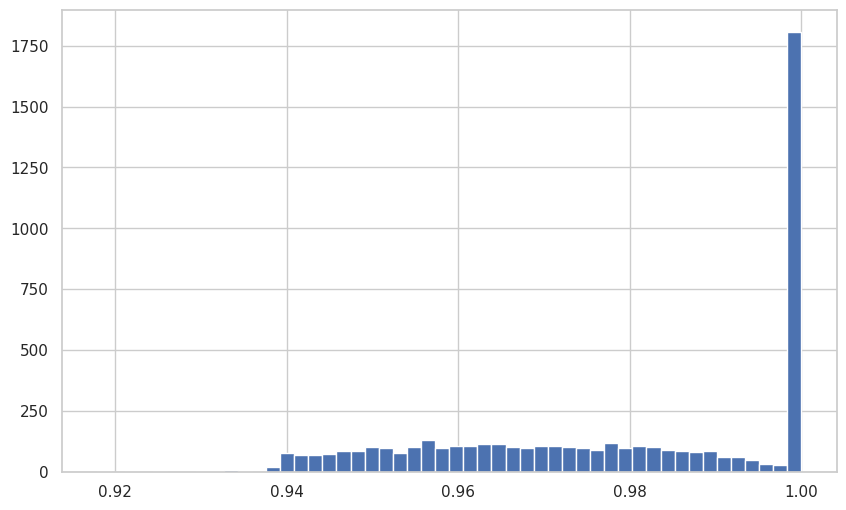

In [28]:
# how many unique clusters?
print("clusters:", dfm['cluster_id'].nunique())

# flag counts
print(dfm['flags'].value_counts().head(20))

# distributions
display(dfm[['chrF_vs_medoid','levenshtein_ratio_vs_medoid','semantic_sim_vs_medoid']].describe())

# histogram of semantic similarity
dfm['semantic_sim_vs_medoid'].hist(bins=50)

## 12) View rows with flags (non-empty flags) and sort by severity (heuristic)

In [29]:
flagged = dfm[dfm['flags'].astype(bool)]
# sort by semantic low but chrF low etc; example sort by semantic ascending then chrF ascending
flagged_sorted = flagged.sort_values(['semantic_sim_vs_medoid','chrF_vs_medoid'], ascending=[True, True])
flagged_sorted[['id','language','cluster_id','medoid_id','flags','chrF_vs_medoid','semantic_sim_vs_medoid']].head(50)

,id,language,cluster_id,medoid_id,flags,chrF_vs_medoid,semantic_sim_vs_medoid
3988,portland-extreme_heat-198,te,29965,portland-extreme_heat-169,sem_high_lex_low,18.742219,0.917883
1770,portland-wildfire-023,kar,14034,portland-wildfire-038,sem_high_lex_low,16.096663,0.918370
3978,portland-extreme_heat-166,te,29965,portland-extreme_heat-169,sem_high_lex_low,18.470319,0.918586
3897,portland-evacuation-047,te,29872,portland-evacuation-141,sem_high_lex_low,20.914466,0.921707
4195,portland-wildfire-033,te,30315,portland-wildfire-085,sem_high_lex_low,15.937586,0.922604
2074,kc-landslides_and_mudflows-114,km,14950,kc-landslides_and_mudflows-074,sem_high_lex_low;entity_issue:bracketed_changed,15.018528,0.925091
4224,portland-winter_weather-005,te,30383,portland-winter_weather-069,sem_high_lex_low,16.341021,0.925533
2753,portland-winter_weather-050,lo,18224,portland-winter_weather-073,sem_high_lex_low,16.400903,0.926062
1954,portland-evacuation-023,km,14436,kc-evacuation-009,sem_high_lex_low,23.240589,0.927395
3901,portland-evacuation-067,te,29872,portland-evacuation-141,sem_high_lex_low,18.705495,0.928106


## 13) Show medoid + member example (print human‑readable)

In [30]:
def show_examples_for_cluster(cluster_label, n=6):
    sub = dfm[dfm['cluster_id'].astype(int) == int(cluster_label)]
    if sub.empty:
        print("No cluster", cluster_label); return
    medoid = sub.iloc[0]['medoid_text']
    print("Cluster", cluster_label, "size:", len(sub))
    print("\nMedoid text:\n", medoid, "\n")
    print("Sample members (id | text | chrF | sem):")
    for _, r in sub.sample(min(n, len(sub))).iterrows():
        print(f"{r['id']} | {r['language']} | chrF={r['chrF_vs_medoid']:.1f} | sem={r['semantic_sim_vs_medoid']:.3f}")
        print(" ->", r['text'][:300])
        print("-----")

# show cluster 10 (example)
show_examples_for_cluster(5, n=8)

Cluster 10 size: 11

Medoid text:
 በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ላይ ያለውን ማቀዝቀዣ ያስኪዱት። 

Sample members (id | text | chrF | sem):
portland-air_quality-145 | am | chrF=14.3 | sem=0.982
 -> በሰደድ እሳት ጭስ የመጣ አመድ በቤትዎ ውስጥ ካገኙ፣ ያፅዱ በእርጥብ ጨርቅ ወይም በእርጥብ መዎልያ።
-----
portland-air_quality-158 | am | chrF=36.9 | sem=0.987
 -> በቤትዎ ውስጥ ያለውን አየር ለማፅዳት የምድጃ ማጣርያን በሳጥን ማቀዝቀዣ ላይ ማጣበቅ ይችላሉ።
-----
portland-air_quality-140 | am | chrF=4.4 | sem=0.958
 -> ምግብ በሚዘጋጅበት ጊዜ ከመጥበስ ወይም ከቀጥተና እሳት መጥበስ ይቆጠቡ።
-----
portland-air_quality-084 | am | chrF=7.4 | sem=0.980
 -> ከፊትዎ ጋር የሚስማማ እና ምንም ክፍተት የሌለበትን የጭምብል ልኬት እና የምር ቱን ስም ይምረጡ።
-----
portland-air_quality-060 | am | chrF=6.3 | sem=0.973
 -> የልብ ወይም የሳንባ በሽታ ካለብዎ፣ ልጅ ወይም ትልቅ ሰው ከሆኑ ወይም ለረጅም ጊዜ ከቤት ውጭ ከሰሩ የበለጠ ለአደጋ ሊጋለጡ ይችላሉ።
-----
portland-air_quality-119 | am | chrF=7.7 | sem=0.968
 -> የካሊፎርኒያ ግዛት ጭስ ከአየር ላይ የሚያፀዱ የተረጋገጡ የአየር ማፅጃዎች ዝርዝር ያቀርባል።
-----
portland-air_quality-152 | am | chrF=6.4 | sem=0.967
 -> በመስኮቱ ወይም በበሩ ስር የሚመጣን ጭስ ለማቆም የተጠቀለለ ፎጣ ይ

## 14) Expand / pivot view: medoid vs member side-by-side

In [31]:
# For a chosen cluster (or top N), build a small DataFrame showing member and medoid text
cluster_to_inspect = 10
sub = dfm[dfm['cluster_id'].astype(int) == cluster_to_inspect].copy()
sub['medoid_text_short'] = sub['medoid_text'].str[:200]
sub['member_text_short'] = sub['text'].str[:200]
sub[['id','language','member_text_short','medoid_text_short','chrF_vs_medoid','semantic_sim_vs_medoid']].head(40)

,id,language,member_text_short,medoid_text_short,chrF_vs_medoid,semantic_sim_vs_medoid
0,portland-air_quality-060,am,የልብ ወይም የሳንባ በሽታ ካለብዎ፣ ልጅ ወይም ትልቅ ሰው ከሆኑ ወይም ለ...,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,6.323220,0.972777
1,portland-air_quality-084,am,ከፊትዎ ጋር የሚስማማ እና ምንም ክፍተት የሌለበትን የጭምብል ልኬት እና ...,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,7.384364,0.979582
2,portland-air_quality-088,am,ጭምብል ማድረግ እንደ አስም ያሉ አንዳንድ የጤና ችግሮች ላለባቸው ሰዎች ...,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,7.042254,0.963053
3,portland-air_quality-100,am,የአየሩ ጥራት ጤናማ ካልሆነ ከቤት ውጭ የሚደረጉ እንቅስቃሴዎችን መሰረዝ ...,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,8.529416,0.966675
4,portland-air_quality-119,am,የካሊፎርኒያ ግዛት ጭስ ከአየር ላይ የሚያፀዱ የተረጋገጡ የአየር ማፅጃዎች...,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,7.736552,0.968144
5,portland-air_quality-126,am,ከቻሉ እባክዎ ጥቂት የአየር ማጣሪያዎችን እና ጭምብሎችን አሁን መደብሮች ...,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,8.345306,0.975369
6,portland-air_quality-140,am,ምግብ በሚዘጋጅበት ጊዜ ከመጥበስ ወይም ከቀጥተና እሳት መጥበስ ይቆጠቡ።,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,4.350736,0.958354
7,portland-air_quality-145,am,በሰደድ እሳት ጭስ የመጣ አመድ በቤትዎ ውስጥ ካገኙ፣ ያፅዱ በእርጥብ ጨር...,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,14.318381,0.981978
8,portland-air_quality-152,am,በመስኮቱ ወይም በበሩ ስር የሚመጣን ጭስ ለማቆም የተጠቀለለ ፎጣ ይጠቀሙ።,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,6.365629,0.967227
9,portland-air_quality-158,am,በቤትዎ ውስጥ ያለውን አየር ለማፅዳት የምድጃ ማጣርያን በሳጥን ማቀዝቀዣ ...,በቤትዎ ውስጥ ያለውን አየር ያለ ሙቀት ለማዟዟር እና ለማጣራት በምድጃዎ ...,36.881983,0.986590


## 15) Interactive HTML table for quick browsing

In [ ]:
# from IPython.display import HTML, display
# def html_table_for_top_clusters(n_clusters=30):
#     rows=[]
#     top_clusters = dfm['cluster_id'].value_counts().head(n_clusters).index.tolist()
#     for cl in top_clusters:
#         sub = dfm[dfm['cluster_id'].astype(int)==int(cl)]
#         med = sub.iloc[0]['medoid_text']
#         members_html = "<br/>".join(sub['id'].tolist())
#         rows.append(f"<tr><td>{cl}</td><td>{len(sub)}</td><td>{med}</td><td style='font-family:monospace'>{members_html}</td></tr>")
#     html = "<table border=1 style='width:100%'><thead><tr><th>cluster</th><th>size</th><th>medoid_text</th><th>members</th></tr></thead><tbody>"
#     html += "".join(rows) + "</tbody></table>"
#     display(HTML(html))

# html_table_for_top_clusters(20)

## 16) Interactive scatter (Plotly) to inspect by cluster / metric (hover shows text)

In [33]:
import plotly.express as px
# Need 2D coordinates to plot; if none available, use semantic vs chrF scatter
fig = px.scatter(dfm, x='semantic_sim_vs_medoid', y='chrF_vs_medoid',
                 color='cluster_id', hover_data=['id','language','text','medoid_id'],
                 title="Semantic vs chrF colored by cluster")
fig.update_traces(marker=dict(size=6))
fig.show()
# optionally save
fig.write_html("semantic_vs_chrf.html")

In [45]:
# One PNG per language with annotations (chrF + semantic), saved individually.
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import math, re, numpy as np

# CONFIG
# CSV_PATH = "analysis_out/flags_vs_medoid.csv"
# OUT_DIR = Path("analysis_out/language_plots_single")
# OUT_DIR.mkdir(parents=True, exist_ok=True)
FIGSIZE = (10,5)         # width, height per language image
DPI = 200
VIOLIN_KW = dict(inner='box', density_norm='width', cut=0)  # removed palette -> no deprecation warning

# helpers
def safe_name(s):
    s = str(s)
    s = re.sub(r'[^\w\-_\. ]', '_', s)
    s = s.replace(" ", "_")
    return s[:120]

# load data
df = pd.read_csv(CSV_PATH, dtype=str).fillna("")
for c in ['chrF_vs_medoid','semantic_sim_vs_medoid','levenshtein_ratio_vs_medoid']:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

# languages to plot (all)
languages = sorted(df['language'].unique())
print("Languages to render:", len(languages))

for lang in languages:
    sub = df[df['language']==lang].copy()
    n = len(sub)
    if n == 0:
        continue

    # compute annotation stats
    sem_median = sub['semantic_sim_vs_medoid'].median() if 'semantic_sim_vs_medoid' in sub else np.nan
    sem_q25 = sub['semantic_sim_vs_medoid'].quantile(0.25) if 'semantic_sim_vs_medoid' in sub else np.nan
    sem_q75 = sub['semantic_sim_vs_medoid'].quantile(0.75) if 'semantic_sim_vs_medoid' in sub else np.nan

    chrf_median = sub['chrF_vs_medoid'].median() if 'chrF_vs_medoid' in sub else np.nan
    chrf_q25 = sub['chrF_vs_medoid'].quantile(0.25) if 'chrF_vs_medoid' in sub else np.nan
    chrf_q75 = sub['chrF_vs_medoid'].quantile(0.75) if 'chrF_vs_medoid' in sub else np.nan

    # percent flagged
    pct_flagged = (sub['flags'].astype(bool).sum() / n) * 100.0 if 'flags' in sub else 0.0

    # create figure with two violins side by side
    fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, constrained_layout=True)
    fig.suptitle(f"Language: {lang}  (n={n})", fontsize=14)

    # chrF violin (0..100)
    ax = axes[0]
    # draw violin for a single categorical 'language' (we use a single color)
    sns.violinplot(data=sub, x='language', y='chrF_vs_medoid', order=[lang], ax=ax, color='tab:blue', **VIOLIN_KW)
    ax.set_ylim(0, 100)
    ax.set_ylabel("chrF_vs_medoid")
    ax.set_xlabel("")
    # annotation text near top-left of subplot
    ax.text(0, 105, f"count={n}\nmedian={chrf_median:.1f}\nIQR={chrf_q25:.1f}-{chrf_q75:.1f}\n% flagged={pct_flagged:.1f}%", 
            fontsize=9, va='top')

    # semantic violin (0..1)
    ax2 = axes[1]
    sns.violinplot(data=sub, x='language', y='semantic_sim_vs_medoid', order=[lang], ax=ax2, color='tab:orange', **VIOLIN_KW)
    ax2.set_ylim(0, 1.0)
    ax2.set_ylabel("semantic_sim_vs_medoid")
    ax2.set_xlabel("")
    ax2.text(0, 1.02, f"median={sem_median:.3f}\nIQR={sem_q25:.3f}-{sem_q75:.3f}", fontsize=9, va='top')

    # optionally annotate outlier counts
    low_chrf_count = int((sub['chrF_vs_medoid'] < 20).sum()) if 'chrF_vs_medoid' in sub else 0
    low_sem_count = int((sub['semantic_sim_vs_medoid'] < 0.6).sum()) if 'semantic_sim_vs_medoid' in sub else 0
    axes[0].annotate(f"low chrF (<20): {low_chrf_count}", xy=(0,5), xycoords='data', fontsize=9, color='red')
    axes[1].annotate(f"low sem (<0.6): {low_sem_count}", xy=(0,0.05), xycoords='data', fontsize=9, color='red')

    # Save PNG: one file per language
    PLOT_OUTPUT_DIR = Path(OUTPUT_DIR) / "language_plots_single"
    PLOT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fname = PLOT_OUTPUT_DIR / f"{safe_name(lang)}.png"
    fig.savefig(fname, dpi=DPI, bbox_inches='tight')
    plt.close(fig)
    print("Saved", fname)

print("All plots written to", PLOT_OUTPUT_DIR)  

Languages to render: 33
Saved /home/jen/TranslationsDataset/analysis_out/language_plots_single/am.png
Saved /home/jen/TranslationsDataset/analysis_out/language_plots_single/ar.png
Saved /home/jen/TranslationsDataset/analysis_out/language_plots_single/chk.png
Saved /home/jen/TranslationsDataset/analysis_out/language_plots_single/en.png
Saved /home/jen/TranslationsDataset/analysis_out/language_plots_single/es.png
Saved /home/jen/TranslationsDataset/analysis_out/language_plots_single/fa.png
Saved /home/jen/TranslationsDataset/analysis_out/language_plots_single/fr.png
Saved /home/jen/TranslationsDataset/analysis_out/language_plots_single/hi.png
Saved /home/jen/TranslationsDataset/analysis_out/language_plots_single/hmn.png
Saved /home/jen/TranslationsDataset/analysis_out/language_plots_single/ium.png
Saved /home/jen/TranslationsDataset/analysis_out/language_plots_single/ja.png
Saved /home/jen/TranslationsDataset/analysis_out/language_plots_single/kar.png
Saved /home/jen/TranslationsDataset/

## 17) Filter heuristics examples (find likely problematic translations)

In [34]:
# Examples: semantic high but low chrF (sem_high_lex_low)
candidates = dfm[(dfm['semantic_sim_vs_medoid'] >= 0.8) & (dfm['chrF_vs_medoid'] < 30)]
len(candidates), candidates.sample(min(10,len(candidates)))[['id','language','chrF_vs_medoid','semantic_sim_vs_medoid','text','medoid_text']]

(1435,
                                id language  chrF_vs_medoid  \
 1917      portland-boil_water-028       km       14.014886   
 3914      portland-evacuation-118       te       20.460621   
 230           kc-power_outage-023       am        5.091104   
 1676           portland-flood-030      kar       23.841785   
 1601    portland-extreme_heat-215      kar       18.829384   
 3874      portland-boil_water-013       te       16.680370   
 2247  portland-winter_weather-040       km       12.230087   
 107     portland-extreme_heat-235       am       14.819303   
 1807        portland-wildfire-058      kar       28.603355   
 3112                  kc-heat-020       pa       13.468862   
 
       semantic_sim_vs_medoid  \
 1917                0.965091   
 3914                0.971282   
 230                 0.963467   
 1676                0.942758   
 1601                0.959178   
 3874                0.952952   
 2247                0.979823   
 107                 0.984449   
 

## 18) Summary per cluster: size, average semantic, avg chrF, number flagged

In [35]:
cluster_summary = dfm.groupby('cluster_id').agg(
    size=('cluster_id','count'),
    avg_semantic=('semantic_sim_vs_medoid','mean'),
    avg_chrf=('chrF_vs_medoid','mean'),
    n_flagged=('flags', lambda s: s.astype(bool).sum())
).sort_values('size', ascending=False)
cluster_summary.head(40)

,size,avg_semantic,avg_chrf,n_flagged
cluster_id,,,,
29965,59,0.973522,15.941862,59
13679,54,0.975412,24.825650,46
13596,49,0.971432,18.516087,48
16976,46,0.972926,22.851557,37
29872,39,0.970223,18.201673,37
13450,38,0.976363,26.877238,29
29722,36,0.974923,15.197177,35
14034,36,0.973955,20.890559,33
30314,36,0.976425,15.759511,36


## 18) Export a small review CSV of high-priority flag cases

In [36]:
REVIEW_CSV = "flags_review.csv"
high_priority = dfm[dfm['flags'].astype(bool)].sort_values(['cluster_id','semantic_sim_vs_medoid'])
high_priority.to_csv(REVIEW_CSV, index=False)
print("Wrote", REVIEW_CSV, "rows:", len(high_priority))

Wrote flags_review.csv rows: 1557


## Next steps and tuning recommendations

- Inspect `analysis_out/clusters.csv` and `analysis_out/flags_vs_medoid.csv`. Start with the flagged items and the largest clusters.
- Calibrate thresholds:
  - Adjust `CLUSTER_DISTANCE_THRESHOLD` to change cluster granularity.
  - Tune semantic (>=0.8) and lexical (chrF thresholds) heuristics in the flags logic.
- If you want per-language NER checks, enable stanza and download appropriate models:
  - Example: `stanza.download('en')` then `stanza.Pipeline('en', processors='tokenize,ner')`
- For very large datasets, process per-scenario or per-language batches to avoid building an NxN matrix for all items at once.